Encrypting image with shape:  (512, 512, 3)


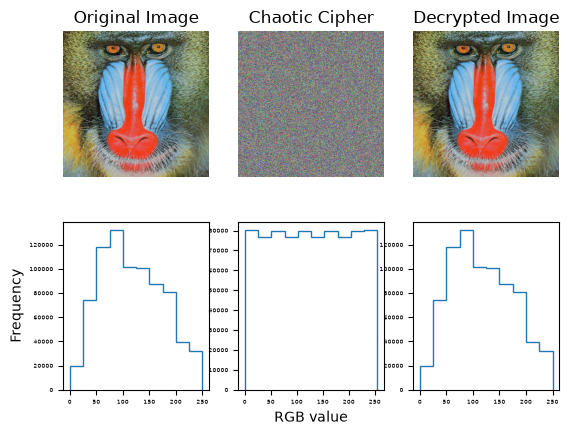

'\nkorrelation\ngrannkorrelation\nuaci och npcr\nentropi\nhistogram\n'

In [2]:
%load_ext autoreload
%autoreload 2
import ImageToMatrix as itm
import matplotlib.pyplot as plt
import numpy as np
from matt_enkel import entropi, korrelation, grannkorrelation
from PIL import Image

'''
korrelation
grannkorrelation
uaci och npcr
entropi
histogram
'''

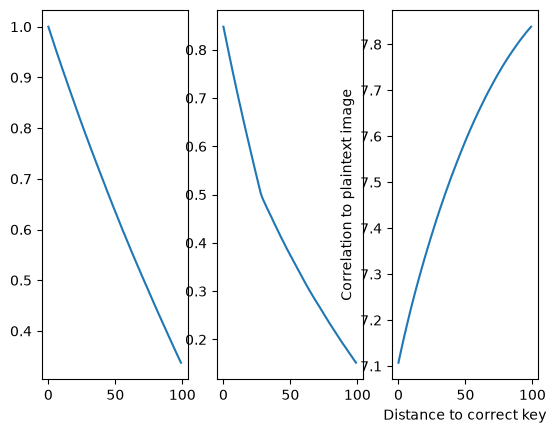

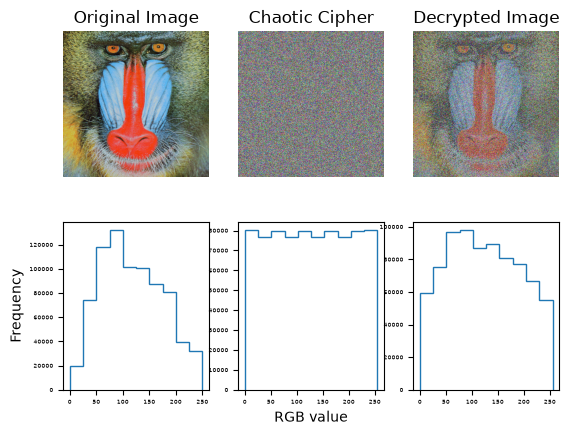

In [ ]:

# Samma bilder som i ImageToMatrix.py
iterations = 100
finetune = 5  # Välj från 1-5, högre värde ger sämre granularitet men större förändring
original = itm.matrix
krypterad = itm.chaoticencryptedArray.reshape(original.shape)
ratt_nycklar = itm.chaotickeys.T
nearMissnycklar = np.empty(
    (iterations + 1, *ratt_nycklar.shape), dtype=ratt_nycklar.dtype
)
tmpnyckel = ratt_nycklar.copy()

for i in range(iterations):
    nearMissnycklar[i] = tmpnyckel.copy()
    start = i * 512 * finetune
    end = start + 512 * finetune  # change one row of pixels at a time
    tmpnyckel[start:end, :] ^= 100 % 256
# for i in range(iterations):
#     nearMissnycklar[i] = tmpnyckel.copy()
#     tmpnyckel[i, :] ^= 120 % 256  # Mindre nogrann större förändring

# --- Dekryptering med rätt nycklar------------------------------------------------------------
# desubstituerad = np.bitwise_xor(krypterad.reshape(-1, 3), ratt_nycklar).reshape(
#     original.shape
# )
desubstituerad = itm.inverseLorenzDiffuse(krypterad, ratt_nycklar)
dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1, 1)
# print(
#      f"Korrelation orig/orig:  {korrelation(original, original):.4f}"
#      f"  Entropi originalbild:   {entropi(original):.4f}"
# )

# # --- Dekryptering med Near-Miss keys ------------------------------------------------------------
nyckelKedja = np.empty((iterations, *original.shape), dtype = np.uint8)
korrarr = np.arange(iterations, dtype=float)
entropiarr = np.arange(iterations, dtype=float)
grannkorrarr = np.arange(iterations, dtype=float)
for i in range(iterations):
    # desubstituerad = np.bitwise_xor(
    #     krypterad.reshape(-1, 3), nearMissnycklar[i]
    # ).reshape(original.shape)
    desubstituerad = itm.inverseLorenzDiffuse(krypterad, nearMissnycklar[i])
    dekrypterad = itm.InverseArnoldCatMapTransform(desubstituerad, 10, 1, 1)
    nyckelKedja[i] = dekrypterad
    korrarr[i] = korrelation(original, dekrypterad)
    entropiarr[i] = entropi(dekrypterad)
    grannkorrarr[i] = grannkorrelation(dekrypterad).get('vertikalt')

    grannkorrelation(dekrypterad)

    # print(
    #     f"Korrelation orig/dekrypterad:  {korrelation(original, dekrypterad):.4f}"
    #     f"  Entropi enkrypteringbild:   {entropi(krypterad):.4f}"
    # )

plt.subplot(1,3,1)
plt.plot(np.arange(iterations), korrarr)

plt.subplot(1,3,2)
plt.plot(np.arange(iterations), grannkorrarr)

plt.subplot(1,3,3)
plt.plot(np.arange(iterations), entropiarr)
plt.xlabel("Distance to correct key")
plt.ylabel("Correlation to plaintext image")
plt.show()
itm.plotImages(original, krypterad, nyckelKedja[-1])


In [15]:

# itm.plotImages(original, krypterad, nyckelKedja[-1])
tmp = tmpnyckel[0, 0].copy()
tmp ^= 128
print(tmp)


175


In [58]:
#stationär i (0, 0, 0)
# print(itm.matrix - itm.ArnoldCatMapTransform(itm.matrix, 10, 1, 1))
# print(itm.matrix)
# print(itm.matrix[0][1][0])
print(ratt_nycklar.shape)
print(nearMissnycklar[0] ^= 256)


SyntaxError: invalid syntax (451487205.py, line 6)